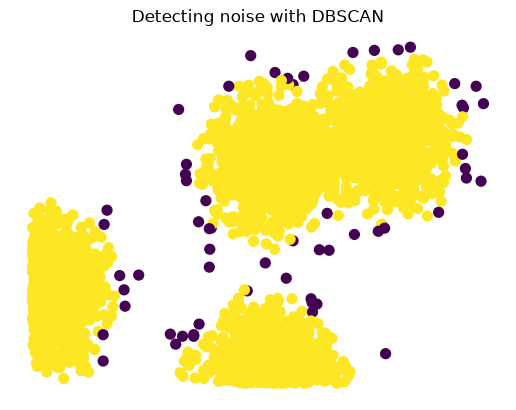

In [5]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

# Indicate the number of points
n_points = 4000

# randomly generating data points and noise
points, y_true = make_blobs(n_samples=n_points,
                            centers=4,
                            cluster_std=0.06,
                            random_state=11,
                            center_box=(0, 1.0))

# only positive points and with three decimals
points = np.round(np.abs(points[:, ::-1]), 3)

# storing points into a csv file
np.savetxt(str(n_points)+"_data.csv", points, delimiter=",",  fmt="%.3f")

# clustering and detecting noise with dbscan
clusters = DBSCAN(eps=0.03, min_samples=10).fit_predict(points)

# plotting noise
plt.figure()
plt.title("Detecting noise with DBSCAN")
plt.scatter(points[:, 0], points[:, 1], c=np.where(clusters==-1, 0, 1), s=50)
plt.xticks([])
plt.yticks([])
plt.box(False)
plt.show()


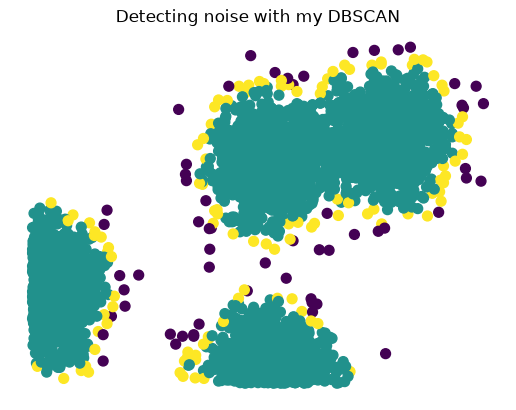

In [6]:
#loading results from c++ program into a numpy array
result = np.loadtxt(str(n_points)+"_results.csv", delimiter=",")

# plotting noise
plt.figure()
plt.title("Detecting noise with my DBSCAN")
plt.scatter(result.T[0], result.T[1], c=result.T[2], s=50)
plt.xticks([])
plt.yticks([])
plt.box(False)
plt.show()

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Leer los resultados crudos
df = pd.read_csv("resultados_tiempos.csv")

# 2. Promediar las 10 iteraciones para cada configuración
df_promedio = df.groupby(["version", "k", "n_puntos", "hilos"])["tiempo_segundos"].mean().reset_index()

# 3. Extraer los tiempos de la versión serial (línea base)
df_serial = df_promedio[df_promedio["version"] == "serial"][["n_puntos", "tiempo_segundos"]]
df_serial = df_serial.rename(columns={"tiempo_segundos": "tiempo_serial"})

# 4. Unir los tiempos seriales con los paralelos para calcular el Speedup
df_comparativa = pd.merge(df_promedio, df_serial, on="n_puntos")
df_comparativa["speedup"] = df_comparativa["tiempo_serial"] / df_comparativa["tiempo_segundos"]

# Filtrar solo las versiones paralelas para las gráficas
df_paralelo = df_comparativa[df_comparativa["version"] != "serial"]

# --- GRÁFICA 1: Speedup vs Hilos (P1 y P2) ---
plt.figure(figsize=(10, 6))
# Para P1
for n in df_paralelo["n_puntos"].unique():
    subset = df_paralelo[(df_paralelo["version"] == "p1") & (df_paralelo["n_puntos"] == n)]
    if not subset.empty:
        plt.plot(subset["hilos"], subset["speedup"], marker='o', linestyle='--', label=f'P1 (N={n})')

# Para P2 (fijando un k, por ejemplo k=16 para comparar)
k_fijo = 16
for n in df_paralelo["n_puntos"].unique():
    subset = df_paralelo[(df_paralelo["version"] == "p2") & (df_paralelo["k"] == k_fijo) & (df_paralelo["n_puntos"] == n)]
    if not subset.empty:
        plt.plot(subset["hilos"], subset["speedup"], marker='s', label=f'P2 k={k_fijo} (N={n})')

plt.axhline(y=1.5, color='r', linestyle=':', label='Meta Speedup (1.5)')
plt.title("Speedup vs Número de Hilos")
plt.xlabel("Número de Hilos")
plt.ylabel("Speedup")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# --- GRÁFICA 2: Speedup vs K (Solo P2) ---
plt.figure(figsize=(10, 6))
# Fijamos un N y un número de hilos para ver el efecto de k
n_fijo = 40000 
hilos_fijo = 8  # Ajusta esto al número de hilos donde obtuviste mejor rendimiento
subset_k = df_paralelo[(df_paralelo["version"] == "p2") & (df_paralelo["n_puntos"] == n_fijo) & (df_paralelo["hilos"] == hilos_fijo)]

if not subset_k.empty:
    plt.plot(subset_k["k"], subset_k["speedup"], marker='^', color='purple')
    plt.title(f"Speedup vs Número de Divisiones (k) - N={n_fijo}, Hilos={hilos_fijo}")
    plt.xlabel("k (Número de regiones)")
    plt.ylabel("Speedup")
    plt.grid(True)
    plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'resultados_tiempos.csv'